# Notebook 14: Federated Masked FedAvg Under Dirichlet Non-IID Skew ($\alpha = 0.5$)

## 1. Aggregation Rule
$$\mathbf{W}^{(t+1)} = \sum_{k \in S_t} \frac{n_k}{\sum_{j \in S_t} n_j} \mathbf{W}_k^{(t+1)}$$
We analyze the real 15-round trajectory recorded in `ml/artifacts/federated_benchmark.json`.

In [1]:
import os, sys, json, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Resolve repository root deterministically from ml/notebooks/
REPO_ROOT = os.path.abspath(os.path.join(os.getcwd(), "..", ".."))
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

DATA_DIR = os.path.join(REPO_ROOT, "ml", "data", "processed")
ARTIFACTS_DIR = os.path.join(REPO_ROOT, "ml", "artifacts")
VIZ_DIR = os.path.join(REPO_ROOT, "ml", "visualizations")
plt.rcParams["figure.dpi"] = 110
with open(os.path.join(ARTIFACTS_DIR, "federated_benchmark.json"), "r") as f:
    bench = json.load(f)

df_fedavg = pd.DataFrame(bench["fedavg_history"])
print(df_fedavg.round(4).to_string(index=False))
print(f"\nFedAvg Peak NDCG@10  : {df_fedavg['ndcg10'].max():.4f} (Round {int(df_fedavg.loc[df_fedavg['ndcg10'].idxmax(), 'round'])})")
print(f"FedAvg Final NDCG@10 : {df_fedavg['ndcg10'].iloc[-1]:.4f} | Std Dev (Drift) = {df_fedavg['ndcg10'].std():.4f}")

 round  ndcg10   hr10    mrr   gini
     1  0.0646 0.1611 0.0635 0.4068
     2  0.0712 0.1948 0.0613 0.2910
     3  0.0592 0.1505 0.0616 0.3555
     4  0.0420 0.1032 0.0563 0.4435
     5  0.0638 0.1043 0.0834 0.5564
     6  0.0944 0.2359 0.0775 0.2199
     7  0.0625 0.1326 0.0717 0.3485
     8  0.0620 0.1566 0.0638 0.2810
     9  0.0705 0.1566 0.0766 0.3407
    10  0.0593 0.1335 0.0676 0.2901
    11  0.0587 0.1548 0.0591 0.4367
    12  0.0739 0.1959 0.0638 0.2237
    13  0.0648 0.1666 0.0630 0.2981
    14  0.0524 0.1455 0.0559 0.2829
    15  0.0500 0.1232 0.0615 0.3528

FedAvg Peak NDCG@10  : 0.0944 (Round 6)
FedAvg Final NDCG@10 : 0.0500 | Std Dev (Drift) = 0.0120


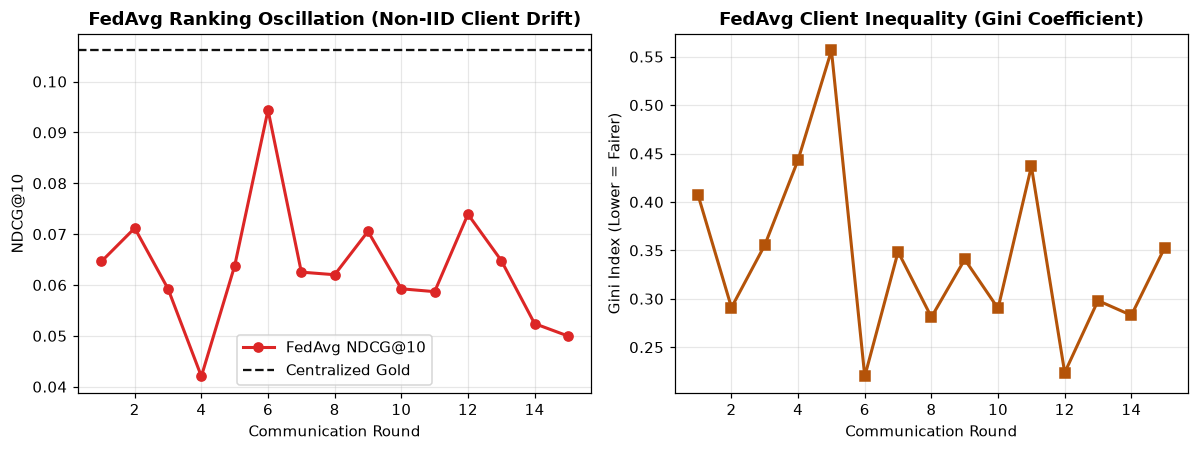

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].plot(df_fedavg["round"], df_fedavg["ndcg10"], "o-", color="#dc2626", lw=2, label="FedAvg NDCG@10")
axes[0].axhline(bench["centralized_baseline"]["ndcg10"], color="#111110", linestyle="--", label="Centralized Gold")
axes[0].set_title("FedAvg Ranking Oscillation (Non-IID Client Drift)", fontweight="bold")
axes[0].set_xlabel("Communication Round")
axes[0].set_ylabel("NDCG@10")
axes[0].grid(alpha=0.3)
axes[0].legend()

axes[1].plot(df_fedavg["round"], df_fedavg["gini"], "s-", color="#b45309", lw=2)
axes[1].set_title("FedAvg Client Inequality (Gini Coefficient)", fontweight="bold")
axes[1].set_xlabel("Communication Round")
axes[1].set_ylabel("Gini Index (Lower = Fairer)")
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()